# Bid-ask bounce and microstructure noise

**Jumps in financial time series, post 3 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| 1 | [Most "jumps" are not jumps](01_jumps_vs_vol_bursts.ipynb) |
| 2 | [Intraday seasonality and false jumps](02_intraday_seasonality.ipynb) |
| **3** | **Bid-ask bounce and microstructure noise** |
| 4 | [Finite or infinite activity](04_jump_activity.ipynb) |
| 5 | [What jump activity does to your hedge](05_hedging_error.ipynb) |
| 6 | [Is volatility rough?](06_rough_volatility.ipynb) |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

The textbook says: at trade level you do not see the efficient price, you see it plus noise, mostly the bounce between bid and ask. The noise inflates realized variance as you sample faster, so you sample every 5 minutes and move on.

I took every trade of seven coins on Binance in October 2026, from Bitcoin down to two football fan tokens that trade once every 20 seconds. Fifty-three million trades.

- **For the illiquid coins the textbook is right, and worse than advertised.** Tick-level realized variance is 19 to 24 times too high. At 5 minutes it is still 2.3 to 2.9 times too high. Five-minute bars are not safe.
- **For Bitcoin the textbook is backwards.** There is no bounce. Tick-level realized variance captures a third of the true variance. Trades arrive in runs and the price trends from trade to trade.
- **Either way, jump measures on raw ticks are noise.** Bipower variation attributes 21% to 56% of variance to jumps. The Lee-Mykland test flags 8,800 jumps a day in BTC and fewer than one in the fan tokens.
- **Averaging the noise out fixes both.** Pre-averaged estimators recover the bar-based volatility of the liquid coins to within a point, and put the jump share of BTC, ETH, SOL and DOGE at zero, give or take two points.

That last number is the missing left end of the curve in post 1.

**Data.** Binance spot aggregated trades for BTC, ETH, SOL, DOGE, CHZ, PSG and ACM against USDT, 1 to 31 October 2026, from the public archive at `data.binance.vision`. No simulation in this post.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import noise as nz
from jumps import plotting as jp

jp.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

COINS = ["BTC", "ETH", "SOL", "DOGE", "CHZ", "PSG", "ACM"]
START, END = "2026-10-01", "2026-10-31"
INTERVALS = {"1h": 3600, "30m": 1800, "15m": 900, "5m": 300, "2m": 120, "1m": 60,
             "30s": 30, "10s": 10, "5s": 5, "2s": 2, "1s": 1}
THETAS = (0.5, 1.0, 2.0)

profile = {c: nz.tick_profile(f"{c}USDT", START, END, INTERVALS, THETAS) for c in COINS}
print(f"{sum(p['records'].sum() for p in profile.values()):,} aggregated trades, "
      f"{len(profile['BTC'])} days, {len(COINS)} coins")

53,141,272 aggregated trades, 31 days, 7 coins


## 1. What a tick is here

Three choices, stated once.

- **Aggregated trades.** Binance's `aggTrades` merge the fills of one taker order that execute at the same price. One record is one order hitting one price level.
- **One tick per timestamp.** An order that walks through several price levels produces several records with the same microsecond timestamp. They are collapsed into one observation at the last price. For BTC that removes more than a third of the records.
- **Trade time.** The noise diagnostics and the pre-averaged estimators work on the sequence of ticks, whatever the time between them. Bar-based measures use previous-tick sampling on a clock grid.

In [2]:
def bps(x):
    return 1e4 * x

ladder = pd.DataFrame({
    c: {
        "Ticks per day": p["ticks"].mean(),
        "Seconds between ticks": 86_400 / p["ticks"].mean(),
        "Tick size (bps of price)": bps(p["tick_size"].median()),
        "Zero returns (%)": 100 * p["zero_share"].mean(),
        "Return autocorrelation, lag 1": p["ac1"].mean(),
        "Trade-sign autocorrelation, lag 1": p["sign_ac1"].mean(),
        "Roll spread (bps)": bps(p["roll"].mean()),
        "Days Roll spread is defined": int(p["roll"].notna().sum()),
    } for c, p in profile.items()}).T
ladder["Ticks per day"] = ladder["Ticks per day"].round(0).astype(int)
ladder["Days Roll spread is defined"] = ladder["Days Roll spread is defined"].astype(int)
ladder.round({"Seconds between ticks": 2, "Tick size (bps of price)": 3, "Zero returns (%)": 1,
              "Return autocorrelation, lag 1": 3, "Trade-sign autocorrelation, lag 1": 2, "Roll spread (bps)": 2})

,Ticks per day,Seconds between ticks,Tick size (bps of price),Zero returns (%),"Return autocorrelation, lag 1","Trade-sign autocorrelation, lag 1",Roll spread (bps),Days Roll spread is defined
BTC,527676,0.16,0.001,59.6,0.001,0.65,0.14,8
ETH,351039,0.25,0.041,52.4,0.008,0.75,0.21,13
SOL,157078,0.55,0.946,62.6,-0.173,0.42,0.50,31
DOGE,95742,0.90,1.227,59.1,-0.106,0.42,0.66,26
CHZ,4778,18.08,7.072,57.8,-0.119,0.34,4.48,31
PSG,3872,22.31,22.936,57.3,-0.480,0.17,30.51,31
ACM,4214,20.50,36.900,56.6,-0.480,0.16,42.83,31


## 2. The noise model, and where it holds

The observed log price of trade $i$ is the efficient price plus noise:

$$Y_i = X_i + \varepsilon_i .$$

If the noise is the bid-ask bounce, $\varepsilon_i = \pm s/2$ depending on whether the trade hit the bid or lifted the ask, and trade-to-trade returns are negatively autocorrelated: a buy at the ask is followed, half the time, by a sell at the bid. Roll (1984) turns that into a spread estimate that needs no quotes:

$$s = 2\sqrt{-\operatorname{Cov}(\Delta Y_t, \Delta Y_{t-1})},$$

defined only when the covariance is negative. With pure bounce and no movement of the efficient price, the lag-1 autocorrelation of returns is $-0.5$.

Read the table from the bottom.

- **PSG and ACM** are the model. Autocorrelation $-0.48$, a hair from the theoretical limit. The Roll spread is 31 and 43 basis points, about one tick (23 and 37 basis points). The price is a coin flip between two adjacent levels.
- **CHZ, DOGE and SOL** show a diluted version: autocorrelation between $-0.11$ and $-0.17$, Roll spread close to half a tick.
- **BTC and ETH** do not fit. Autocorrelation is zero to two decimals. The Roll spread is undefined on most days because the covariance has the wrong sign. The tick is a thousandth of a basis point for BTC, so there is no grid to bounce on.

What BTC and ETH have instead is in the next column: trade signs with an autocorrelation of 0.65 and 0.75. Orders are split and arrive in runs of the same side, and each trade in a run nudges the price a little further.

## 3. What noise does to realized variance

Under the bounce model each tick return is $\Delta X_i + \varepsilon_i - \varepsilon_{i-1}$, so with $n$ ticks and noise variance $\omega^2$,

$$E[\mathrm{RV}] \approx \int_0^1 \sigma_s^2\,ds + 2\,n\,\omega^2 .$$

The second term grows with the number of observations. That is the blow-up. The chart shows realized variance at every clock from 30 minutes down to every trade, divided by the noise-robust estimate of section 4.

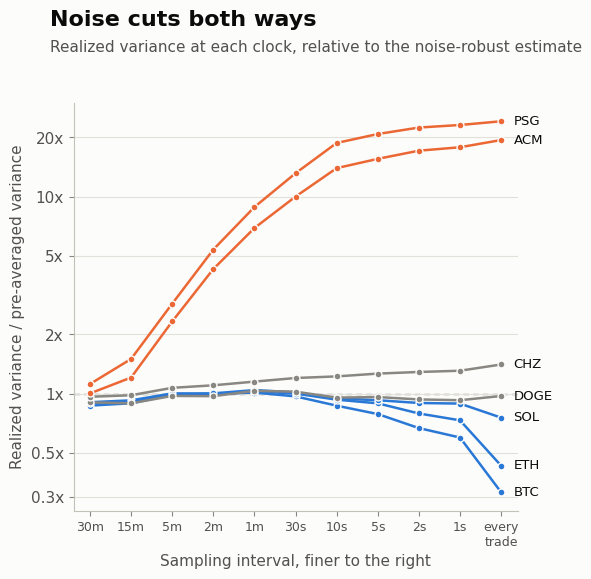

In [3]:
def mean_ratio(p, column, base="rv_star_1.0"):
    return p[column].mean() / p[base].mean()

clocks = [k for k in INTERVALS if k != "1h"]
labels = clocks + ["every\ntrade"]
group_colour = {"BTC": jp.BLUE, "ETH": jp.BLUE, "SOL": jp.BLUE, "DOGE": jp.MUTED, "CHZ": jp.MUTED,
                "PSG": jp.ORANGE, "ACM": jp.ORANGE}
series = [{"name": c, "color": group_colour[c],
           "y": [mean_ratio(p, f"rv_{k}") for k in clocks] + [mean_ratio(p, "rv")]}
          for c, p in profile.items()]
fig = jp.signature_plot(
    series, labels,
    title="Noise cuts both ways",
    subtitle="Realized variance at each clock, relative to the noise-robust estimate",
    ylabel="Realized variance / pre-averaged variance",
    xlabel="Sampling interval, finer to the right",
    yticks=[0.3, 0.5, 1, 2, 5, 10, 20],
)
jp.save(fig, "03_signature");

In [4]:
def vol(x):
    """Annualised volatility in percent from a mean daily variance."""
    return 100 * np.sqrt(365 * x)

variance = pd.DataFrame({
    c: {
        "Volatility, every trade (%)": vol(p["rv"].mean()),
        "Volatility, 5-minute bars (%)": vol(p["rv_5m"].mean()),
        "Volatility, 30-minute bars (%)": vol(p["rv_30m"].mean()),
        "Volatility, pre-averaged (%)": vol(p["rv_star_1.0"].mean()),
        "Variance ratio, every trade": mean_ratio(p, "rv"),
        "Variance ratio, 5-minute bars": mean_ratio(p, "rv_5m"),
        "Noise std (bps)": bps(np.sqrt(max(p["omega2"].mean(), 0.0))),
        "Volatility predicted by IV + 2 n w^2 (%)": vol(p["rv_star_1.0"].mean() + 2 * (p["ticks"] * p["omega2"]).mean()),
    } for c, p in profile.items()}).T
variance.round(2)

,"Volatility, every trade (%)","Volatility, 5-minute bars (%)","Volatility, 30-minute bars (%)","Volatility, pre-averaged (%)","Variance ratio, every trade","Variance ratio, 5-minute bars",Noise std (bps),Volatility predicted by IV + 2 n w^2 (%)
BTC,18.62,33.14,31.48,33.06,0.32,1.00,0.03,33.71
ETH,30.58,46.21,43.41,46.51,0.43,0.99,0.08,48.10
SOL,47.39,54.37,51.73,54.46,0.76,1.00,0.25,60.52
DOGE,58.22,58.25,56.12,58.97,0.97,0.98,0.33,66.16
CHZ,86.62,75.58,71.74,72.99,1.41,1.07,2.37,85.81
PSG,261.15,90.02,56.31,53.18,24.11,2.87,15.36,261.81
ACM,387.00,134.16,88.13,87.94,19.37,2.33,21.59,385.78


Two regimes, in one picture.

**The fan tokens are the textbook.** Every trade of PSG gives a volatility of 261% a year. The noise-robust figure is 53%. The formula above, fed with the measured noise, predicts 261%. And the blow-up does not stop at the frequencies people consider safe: 5-minute bars still give 90% for PSG and 134% for ACM, 1.5 to 1.7 times the right number in volatility terms. Only at 30 minutes does the bias fade.

**Bitcoin goes the other way.** Every trade gives 18.6%. Five-minute bars give 33.1%. The pre-averaged estimate gives 33.1%. Sampling faster does not add noise variance, it removes signal: the tick-level path is too smooth, because consecutive price changes point the same way more often than a random walk allows. A random walk has the same variance per unit of time at every clock. This path has less of it the closer you look. The bounce formula, applied to BTC anyway, predicts 33.7% at tick level where the data say 18.6%. The model has the wrong sign.

The next cell shows that directly. Bounce lives at lag 1. Persistence lives at lags 2 to 50.

In [5]:
from jumps.data import iter_agg_trades

LAGS = [1, 2, 3, 5, 10, 20, 50]
acf = {}
for c in COINS:
    per_day = []
    for _, trades in iter_agg_trades(f"{c}USDT", START, END):
        r = np.diff(nz.to_ticks(trades)[1])
        r = r - r.mean()
        per_day.append([np.mean(r[l:] * r[:-l]) / np.mean(r * r) for l in LAGS])
    acf[c] = np.mean(per_day, axis=0)
pd.DataFrame(acf, index=pd.Index(LAGS, name="Lag, in ticks")).T.round(3)

"Lag, in ticks",1,2,3,5,10,20,50
BTC,0.001,0.079,0.070,0.053,0.039,0.018,0.007
ETH,0.008,0.094,0.085,0.067,0.042,0.015,0.003
SOL,-0.173,0.069,0.046,0.025,0.011,0.003,0.001
DOGE,-0.106,0.066,0.037,0.016,0.005,0.001,-0.002
CHZ,-0.119,0.000,0.000,-0.005,0.001,-0.008,0.003
PSG,-0.480,0.006,-0.007,-0.006,-0.007,0.003,-0.002
ACM,-0.480,0.009,-0.005,-0.006,-0.004,-0.006,-0.007


For BTC and ETH every autocorrelation from lag 2 to lag 50 is positive, and the sum of many small positive terms is what the tick-level variance is missing. For PSG and ACM there is one large negative term at lag 1 and nothing after it.

So "microstructure noise" is two different things in this sample. For a coin whose tick is wide against its price, it is bounce: the observed price overshoots the efficient one on every trade. For a coin whose tick is negligible, it is persistence: the observed price creeps towards the efficient one a trade at a time.

## 4. Averaging it out

The fix does not depend on which kind it is. Do not try to clean each trade. Replace each price by a local average and work with the returns between averages. Bounce flips sign at random inside the window and cancels. A creeping price is caught up with by the time the window ends. A real jump shifts the level, and survives.

The estimators are those of Jacod, Li, Mykland, Podolskij and Vetter (2009) and Podolskij and Vetter (2009), in the form used by Christensen, Oomen and Podolskij (2014). With $N$ tick returns in the day and an even window $K = \theta\sqrt{N}$, the pre-averaged return starting at tick $i$ is

$$r^*_{i,K} = \frac{1}{K}\left(\sum_{j=K/2}^{K-1} Y_{i+j} \;-\; \sum_{j=0}^{K/2-1} Y_{i+j}\right),$$

half the difference between the mean of the second half of the window and the mean of the first. The noise-robust realized variance and bipower variation are

$$\mathrm{RV}^* = \frac{N}{N-K+2}\,\frac{1}{K\psi_K}\sum_{i=0}^{N-K+1} |r^*_{i,K}|^2 \;-\; \frac{\hat\omega^2}{\theta^2\psi_K},$$

$$\mathrm{BV}^* = \frac{N}{N-2K+2}\,\frac{1}{K\psi_K}\,\frac{\pi}{2}\sum_{i=0}^{N-2K+1} |r^*_{i,K}|\,|r^*_{i+K,K}| \;-\; \frac{\hat\omega^2}{\theta^2\psi_K},$$

with $\psi_K = (1 + 2K^{-2})/12$ and the noise variance estimated from the first-order autocovariance of tick returns, $\hat\omega^2 = -\frac{1}{N-1}\sum_i r_i r_{i-1}$. The last term removes the little noise that survives the averaging. The window uses $\theta = 1$ unless stated, inside the range of 0.5 to 2 the authors recommend. For BTC that is 726 ticks, about two minutes of trading. For ACM it is 64 ticks, about twenty minutes.

The table above is the first check: for the four liquid coins the pre-averaged volatility matches the 5-minute figure to within a point, from a completely different use of the data.

## 5. Jumps, before and after

Now the jump measures, on the same month of trades, at three clocks: every trade taken raw, 5-minute bars, and every trade after pre-averaging.

,"Every trade, raw",5-minute bars,"Every trade, pre-averaged"
Jump share of variance (%),,,
BTC,56.2,7.4,-1.0
ETH,44.4,10.5,-1.3
SOL,31.9,8.9,-1.9
DOGE,27.4,7.7,-0.4
CHZ,29.5,11.2,0.9
PSG,20.9,13.5,11.8
ACM,21.3,15.8,7.6


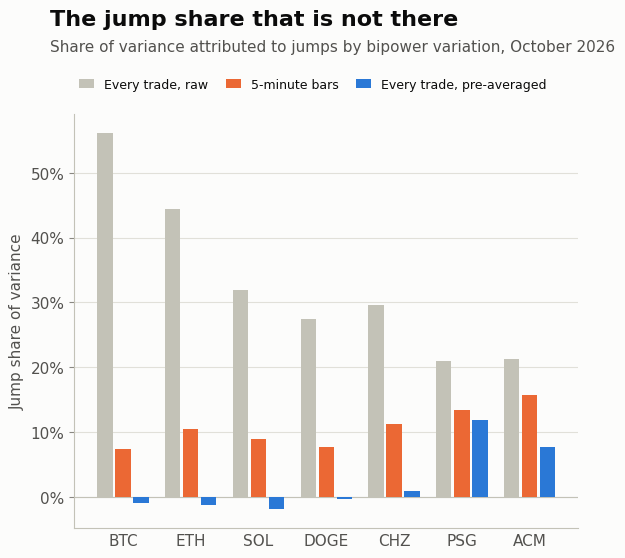

In [6]:
def jump_share(p, rv, bv):
    return 100 * (1 - p[bv].sum() / p[rv].sum())

share = pd.DataFrame({
    "Every trade, raw": [jump_share(p, "rv", "bv") for p in profile.values()],
    "5-minute bars": [jump_share(p, "rv_5m", "bv_5m") for p in profile.values()],
    "Every trade, pre-averaged": [jump_share(p, "rv_star_1.0", "bv_star_1.0") for p in profile.values()],
}, index=COINS)
fig = jp.grouped_bars(
    COINS,
    [{"name": "Every trade, raw", "y": share["Every trade, raw"], "color": jp.AXIS},
     {"name": "5-minute bars", "y": share["5-minute bars"], "color": jp.ORANGE},
     {"name": "Every trade, pre-averaged", "y": share["Every trade, pre-averaged"], "color": jp.BLUE}],
    title="The jump share that is not there",
    subtitle="Share of variance attributed to jumps by bipower variation, October 2026",
    ylabel="Jump share of variance",
)
jp.save(fig, "03_jump_share")
share.round(1).rename_axis("Jump share of variance (%)")

On raw ticks, bipower variation says that a fifth to a half of all variance is jumps. It is an artefact of zero returns. More than half of all tick returns are exactly zero, since consecutive trades often print at the same price, and bipower variation multiplies neighbours: one zero kills two products. Realized variance does not care. The gap between the two is booked as jumps.

On 5-minute bars the figure is 7% to 16%, the range post 1 found on nine years of data.

After pre-averaging it is between $-2\%$ and $+1\%$ for BTC, ETH, SOL, DOGE and CHZ. A share cannot be negative; the estimator can, and its sampling error on one month is of that order. The reading is zero.

The two fan tokens keep 8% and 12%. Before reading that as jumps, look at the window: 64 trades is twenty minutes for these coins. A pre-averaged return over twenty minutes is a 20-minute bar by another name, and post 1 applies to it in full.

### The same comparison with a test that dates each jump

The Lee-Mykland test of post 2, at the 1% level per day, applied three ways: to 5-minute returns with $K = 270$, to raw tick returns, and to non-overlapping pre-averaged returns, which is the tick-level version proposed by Christensen, Oomen and Podolskij. In each case the window follows Lee and Mykland's rule for the number of returns per day, and the days are chained because the market never closes.

In [7]:
detections = {c: nz.tick_detections(f"{c}USDT", START, END, THETAS) for c in COINS}
table = pd.DataFrame({
    c: {
        "Jumps per day, 5-minute bars": d["bars_per_day"],
        "Jumps per day, raw ticks": d["raw_per_day"],
        "Jumps per day, pre-averaged ticks": d["pre_per_day_1.0"],
        "Their share of variance, 5-minute bars (%)": 100 * d["bars_jv"],
        "Their share of variance, raw ticks (%)": 100 * d["raw_jv"],
        "Their share of variance, pre-averaged (%)": 100 * d["pre_jv_1.0"],
        "Ticks per pre-averaging block": d["block_ticks"],
        "Blocks per day": d["blocks_per_day"],
    } for c, d in detections.items()}).T
table.round({"Jumps per day, 5-minute bars": 2, "Jumps per day, raw ticks": 1, "Jumps per day, pre-averaged ticks": 2,
             "Their share of variance, 5-minute bars (%)": 1, "Their share of variance, raw ticks (%)": 1,
             "Their share of variance, pre-averaged (%)": 1, "Ticks per pre-averaging block": 0, "Blocks per day": 0})

,"Jumps per day, 5-minute bars","Jumps per day, raw ticks","Jumps per day, pre-averaged ticks","Their share of variance, 5-minute bars (%)","Their share of variance, raw ticks (%)","Their share of variance, pre-averaged (%)",Ticks per pre-averaging block,Blocks per day
BTC,1.87,8843.7,3.29,18.2,77.1,2.6,726.0,727.0
ETH,2.00,5584.6,0.71,25.7,63.2,2.7,592.0,593.0
SOL,1.87,209.6,0.06,19.3,11.3,0.3,396.0,397.0
DOGE,1.77,188.2,0.26,24.1,21.7,1.4,310.0,309.0
CHZ,1.74,23.8,0.06,20.6,12.6,1.5,70.0,68.0
PSG,0.77,0.6,1.06,11.6,0.3,30.4,62.0,62.0
ACM,1.00,0.9,0.77,16.5,0.7,20.8,64.0,66.0


**Raw ticks: the test measures the noise, not the price.** In BTC it flags 8,800 returns a day and assigns them three quarters of the variance. With most returns at zero, the local bipower volatility is tiny and any real price change towers over it. In the fan tokens it flags fewer than one a day: the bounce is so large that it *is* the local volatility, and no jump can stand out against it. Noise creates jumps in one coin and hides them in another.

**Five-minute bars:** about two jumps a day in the liquid coins, carrying a fifth to a quarter of the variance. The same order as post 2.

**Pre-averaged ticks:** for SOL, DOGE and CHZ the count falls from about 1.8 a day to between 0.06 and 0.26, and the variance they carry from about 20% to under 2%. For ETH it falls to 0.7 a day and 2.7%. For BTC the count does not fall, at 3.3 a day, but the weight does: 2.6% of variance instead of 18%. At tick level BTC has frequent, small discontinuities, the footprint of a large order clearing several price levels at once. They are real, and they are a rounding error in the variance.

### The left end of post 1's curve

Post 1 plotted the jump share of BTC against bar size and stopped at 1 minute, where the curve had started to turn up. Here is the whole curve for October 2026, down to every trade.

,1h,30m,15m,5m,2m,1m,30s,10s,5s,2s,1s,every trade
BTC jump share (%),14.2,10.5,15.0,7.4,5.3,5.6,8.2,16.4,26.3,41.8,52.3,56.2


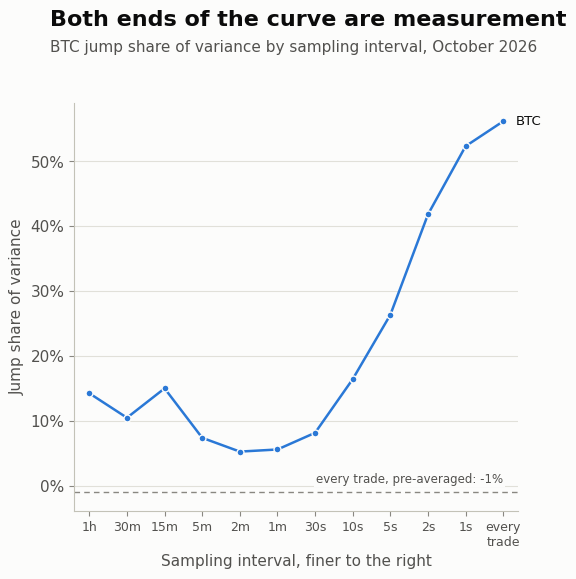

In [8]:
btc = profile["BTC"]
all_labels = list(INTERVALS) + ["every\ntrade"]
curve = [jump_share(btc, f"rv_{k}", f"bv_{k}") for k in INTERVALS] + [jump_share(btc, "rv", "bv")]
robust = jump_share(btc, "rv_star_1.0", "bv_star_1.0")
fig = jp.signature_plot(
    [{"name": "BTC", "y": curve, "color": jp.BLUE}], all_labels,
    title="Both ends of the curve are measurement",
    subtitle="BTC jump share of variance by sampling interval, October 2026",
    ylabel="Jump share of variance", xlabel="Sampling interval, finer to the right",
    reference=robust, reference_label=f"every trade, pre-averaged: {robust:.0f}%",
    log=False, percent=True,
)
jp.save(fig, "03_btc_jump_share_curve")
pd.Series(curve, index=[l.replace("\n", " ") for l in all_labels]).round(1).rename("BTC jump share (%)").to_frame().T

The curve is a U. On the left, with coarse bars, a move that takes several minutes sits inside one return and is booked as a jump: post 1. On the right, with fine sampling, zero returns starve bipower variation: this post. The minimum, around 1 to 2 minutes, is 5%. The uptick post 1 saw at 1 minute on nine years of data is the foot of the right-hand wall.

The noise-robust estimate on every trade is the dashed line, at $-1\%$. Christensen, Oomen and Podolskij found about 1% on equity and currency ticks. On one month of Bitcoin it is zero to within the error of the method.

## 6. Does it depend on the window?

Pre-averaging has one knob, $\theta$. Results that move with it should not be trusted.

In [9]:
rows = {}
for c, p in profile.items():
    d = detections[c]
    for th in THETAS:
        rows[(c, f"theta = {th}")] = {
            "Volatility (%)": vol(p[f"rv_star_{th}"].mean()),
            "Jump share (%)": jump_share(p, f"rv_star_{th}", f"bv_star_{th}"),
            "Jumps flagged per day": d[f"pre_per_day_{th}"],
            "Their share of variance (%)": 100 * d[f"pre_jv_{th}"],
        }
pd.DataFrame(rows).T.round(2)

Volatility (%)  Jump share (%)  Jumps flagged per day  Their share of variance (%)
BTC  theta = 0.5           32.43           -2.19                   6.77                         2.29
     theta = 1.0           33.06           -1.00                   3.29                         2.60
     theta = 2.0           33.41           -0.16                   1.29                         2.73
ETH  theta = 0.5           46.38           -1.75                   0.84                         1.64
     theta = 1.0           46.51           -1.35                   0.71                         2.69
     theta = 2.0           46.72           -1.17                   0.45                         1.91
SOL  theta = 0.5           54.12           -2.22                   0.23                         0.82
     theta = 1.0           54.46           -1.94                   0.06                         0.31
     theta = 2.0           54.86           -1.36                   0.03                         0.22
DOGE theta = 0.5           59.00           -0.57                   0.42                         1.26
     theta = 1.0           58.97           -0.36                   0.26                         1.43
     theta = 2.0           59.16           -1.94                   0.13                         1.00
CHZ  theta = 0.5           73.03            3.06                   0.19                         2.63
     theta = 1.0           72.99            0.91                   0.06                         1.45
     theta = 2.0           72.93           -0.10                   0.06                         3.44
PSG  theta = 0.5           51.55            9.93                   1.19                        22.41
     theta = 1.0           53.18           11.80                   1.06                        30.41
     theta = 2.0           57.01           12.77                   0.48                        28.29
ACM  theta = 0.5           88.11           11.07                   0.94                        16.04
     theta = 1.0           87.94            7.64                   0.77                        20.84
     theta = 2.0           87.45            5.96                   0.39                        22.67

Volatility is stable across the three windows for every coin but PSG. The jump share of the five liquid coins stays within three points of zero. Counts of flagged jumps are the fragile output: BTC goes from 6.8 a day to 1.3 as the window widens. A statement about how *many* jumps there are at tick level depends on the window. A statement about how much *variance* they carry does not: between 0.2% and 3.4% for the five liquid coins at every setting.

## 7. Caveats

- **One month.** October 2026, 31 days. The tick-level results are a deep dive, not a history. The bar-based numbers of posts 1 and 2 cover nine years.
- **Trades only.** There is no mid-quote to compare against. The noise-robust estimator plays that role, and its agreement with 1 to 5-minute realized variance for the liquid coins is the evidence that it works.
- **Trade time.** Pre-averaging uses a fixed number of ticks, so a window is short when the market is busy and long when it is quiet. That absorbs part of the intraday seasonality of post 2, and it is why 64 ticks means twenty minutes for a fan token.
- **Zero returns.** 52% to 63% of tick returns are zero in every coin, liquid or not. They push raw bipower variation down and create a spurious jump share. Any tick-level bipower number that is not pre-averaged should be assumed wrong.
- **The noise is not independent for BTC and ETH.** The theory behind pre-averaging is written for noise with short memory. Persistence over tens of ticks is still short against a window of several hundred, and the volatility check supports that, but it is an empirical statement, not a theorem.
- **Same-timestamp records are collapsed**, and aggregated trades already merge fills at one price. Raw trade prints would show more zero returns and more same-direction runs, and make the raw-tick numbers worse.
- **Another noise-robust test exists.** Lee and Mykland (2012) average prices in blocks and compare block means against one variance for the whole day. I used the pre-averaged form of their 2008 test because it keeps a local volatility, and post 2 showed what a single daily level does to the clock of detections.

## 8. Takeaways

1. "Sample at 5 minutes to avoid noise" is a rule for liquid assets. For a coin that bounces between two ticks, 5-minute realized variance is still more than twice too high.
2. For Bitcoin the noise has the opposite sign. Tick-level realized variance captures a third of the variance, because order flow comes in runs and the price trends from trade to trade.
3. Raw tick data makes jump measures meaningless in both directions: 8,800 false jumps a day in BTC, none found in the fan tokens.
4. Pre-averaging recovers the volatility, 33.1% against 33.1% for BTC, and puts the jump share of the liquid coins at zero.
5. Post 1's curve is a U, and both arms are measurement. The answer was at the bottom, and then lower.

## Equation images for the post

In [10]:
jp.render_equation(r"Y_i = X_i + \varepsilon_i", "03_eq_noise",
                   "Observed price = efficient price + noise", fontsize=28)
jp.render_equation(r"s = 2\,\sqrt{-\mathrm{Cov}(\Delta Y_t,\ \Delta Y_{t-1})}", "03_eq_roll",
                   "Roll (1984): the spread implied by the bounce", fontsize=24)
jp.render_equation(r"r^*_{i,K}=\dfrac{1}{K}\ \sum_{j=K/2}^{K-1}Y_{i+j}\ -\ \dfrac{1}{K}\ \sum_{j=0}^{K/2-1}Y_{i+j}", "03_eq_preaveraged",
                   "Pre-averaged return: second half of the window minus the first", fontsize=20);

## References

- Jacod, J., Li, Y., Mykland, P. A., Podolskij, M. and Vetter, M. (2009). Microstructure noise in the continuous case: The pre-averaging approach. *Stochastic Processes and their Applications*, 119(7), 2249-2276. [doi:10.1016/j.spa.2008.11.004](https://doi.org/10.1016/j.spa.2008.11.004)
- Christensen, K., Oomen, R. C. A. and Podolskij, M. (2014). Fact or friction: Jumps at ultra high frequency. *Journal of Financial Economics*, 114(3), 576-599. [arXiv:2602.10925](https://arxiv.org/abs/2602.10925)
- Podolskij, M. and Vetter, M. (2009). Estimation of volatility functionals in the simultaneous presence of microstructure noise and jumps. *Bernoulli*, 15(3), 634-658. [arXiv:0909.0827](https://arxiv.org/abs/0909.0827)
- Roll, R. (1984). A simple implicit measure of the effective bid-ask spread in an efficient market. *Journal of Finance*, 39(4), 1127-1139. [doi:10.1111/j.1540-6261.1984.tb03897.x](https://doi.org/10.1111/j.1540-6261.1984.tb03897.x)
- Lee, S. S. and Mykland, P. A. (2012). Jumps in equilibrium prices and market microstructure noise. *Journal of Econometrics*, 168(2), 396-406. [doi:10.1016/j.jeconom.2012.03.001](https://doi.org/10.1016/j.jeconom.2012.03.001)

The pre-averaged estimators and the tick-level test are implemented from equations (8) to (11) and (21) of Christensen, Oomen and Podolskij, checked against the arXiv text.

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*